# Task 3: Network Intrusion Detection

## 1. Project Overview

### Objective
The goal of this project is to build a Machine Learning model that identifies whether network traffic is **normal or malicious (an attack)** using the UNSW-NB15 dataset.

### Dataset
The UNSW-NB15 dataset contains network traffic records with features such as protocol, connection state, packet counts, data transfer rates, and other network statistics.

### Tools and Libraries
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

### Project Workflow
1. Load and inspect the dataset.
2. Perform data quality checks and exploratory data analysis.
3. Prepare features and the target variable.
4. Encode categorical features and apply appropriate scaling.
5. Split data and use cross-validation.
6. Train a baseline model and compare it with stronger models.
7. Evaluate performance using Precision, Recall, F1-score, ROC-AUC, and a confusion matrix.
8. Visualize results and analyze model limitations.
9. Save the trained model and document the project in a README.

### Evaluation and Data Leakage Prevention
The model will be evaluated on unseen test data. Preprocessing steps such as encoding and scaling will be fitted only on training data through a Scikit-learn pipeline to prevent data leakage.

### Expected Outcome
A reproducible binary classification model that detects potential network attacks, compares its performance against a baseline, and documents its strengths and limitations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("data/UNSW_NB15_training-set.csv")

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)
print("\nFirst 5 rows:")
display(train_df.head())

Dataset loaded successfully!
Shape: (175341, 45)

First 5 rows:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [2]:
print("Dataset shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nMissing values:")
print(train_df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", train_df.duplicated().sum())

print("\nTarget distribution:")
print(train_df["label"].value_counts())

print("\nTarget distribution (%):")
print((train_df["label"].value_counts(normalize=True) * 100).round(2))

print("\nAttack categories:")
print(train_df["attack_cat"].value_counts())

Dataset shape: (175341, 45)

Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Data types:
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                

In [3]:
print("Label values:")
print(sorted(train_df["label"].unique()))

print("\nCategorical feature summaries:")
for col in ["proto", "service", "state"]:
    print(f"\n{col}: {train_df[col].nunique()} unique values")
    print(train_df[col].value_counts().head(10))

print("\nTarget vs attack category:")
display(pd.crosstab(train_df["attack_cat"], train_df["label"]))

Label values:
[np.int64(0), np.int64(1)]

Categorical feature summaries:

proto: 133 unique values
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
ipv6        201
Name: count, dtype: int64

service: 13 unique values
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
Name: count, dtype: int64

state: 9 unique values
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

Target vs attack category:


label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


## 3. Feature and Target Selection

The target variable is `label`, where `0` represents normal traffic and `1` represents an attack.

The `id` column is removed because it is a record identifier rather than a meaningful traffic feature. The `attack_cat` column is also excluded because it directly reveals whether a record is normal or an attack, causing target leakage.

The remaining columns will be used as input features. Categorical features will be encoded, and numerical features will be scaled where appropriate as part of a Scikit-learn preprocessing pipeline.

In [4]:
X_train = train_df.drop(columns=["id", "attack_cat", "label"])
y_train = train_df["label"]

print("Feature shape:", X_train.shape)
print("Target shape:", y_train.shape)

print("\nTarget distribution:")
print(y_train.value_counts())

Feature shape: (175341, 42)
Target shape: (175341,)

Target distribution:
label
1    119341
0     56000
Name: count, dtype: int64


In [5]:
test_df = pd.read_csv("data/UNSW_NB15_testing-set.csv")

X_test = test_df.drop(columns=["id", "attack_cat", "label"])
y_test = test_df["label"]

print("Test dataset shape:", test_df.shape)
print("Test feature shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nTraining and testing feature columns match:",
      X_train.columns.equals(X_test.columns))

Test dataset shape: (82332, 45)
Test feature shape: (82332, 42)
Test target shape: (82332,)

Test target distribution:
label
1    45332
0    37000
Name: count, dtype: int64

Training and testing feature columns match: True


In [6]:
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Number of categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print(numerical_features)

Number of categorical features: 3
['proto', 'service', 'state']

Number of numerical features: 39
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Model Performance")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_test, baseline_predictions):.4f}")
print(f"Precision: {precision_score(y_test, baseline_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, baseline_predictions, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, baseline_predictions, zero_division=0):.4f}")

Baseline Model Performance
------------------------------
Accuracy:  0.5506
Precision: 0.5506
Recall:    1.0000
F1-Score:  0.7102


In [9]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Performance")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, lr_predictions):.4f}")
print(f"Precision: {precision_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, lr_probabilities):.4f}")

Logistic Regression Performance
-----------------------------------
Accuracy:  0.8100
Precision: 0.7537
Recall:    0.9728
F1-Score:  0.8493
ROC-AUC:   0.9558


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Performance")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, rf_predictions):.4f}")
print(f"Precision: {precision_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_probabilities):.4f}")

Random Forest Performance
-----------------------------------
Accuracy:  0.8705
Precision: 0.8166
Recall:    0.9862
F1-Score:  0.8934
ROC-AUC:   0.9789


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("Random Forest Cross-Validation Results")
print("-" * 45)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.upper():10}: "
        f"{scores.mean():.4f} (+/- {scores.std():.4f})"
    )

Random Forest Cross-Validation Results
---------------------------------------------
ACCURACY  : 0.9579 (+/- 0.0002)
PRECISION : 0.9609 (+/- 0.0004)
RECALL    : 0.9781 (+/- 0.0003)
F1        : 0.9694 (+/- 0.0001)
ROC_AUC   : 0.9933 (+/- 0.0002)


## 11. Model Performance Comparison

This section compares all trained models using the official test dataset.

The comparison helps identify which model performs best for network intrusion detection.

We consider precision, recall, F1-score, and ROC-AUC alongside accuracy because detecting attacks while controlling false alarms is important in intrusion detection.

In [12]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1-Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ],
    "ROC-AUC": [
        np.nan,
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

comparison = comparison.round(4)
comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline,0.5506,0.5506,1.0000,0.7102,NaN
1,Logistic Regression,0.8100,0.7537,0.9728,0.8493,0.9558
2,Random Forest,0.8705,0.8166,0.9862,0.8934,0.9789


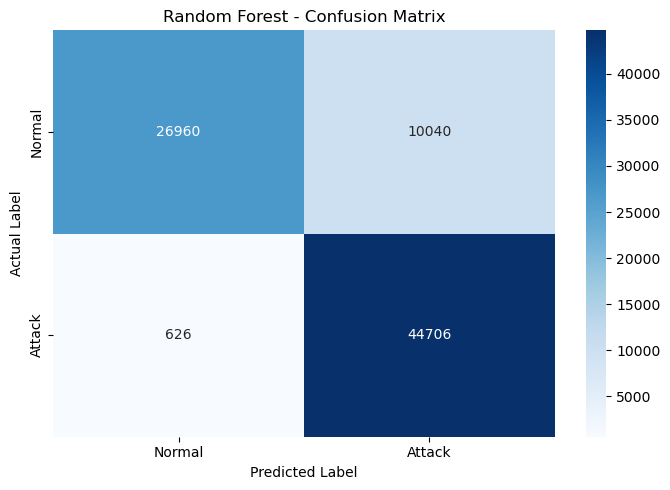

Confusion Matrix Details
------------------------------
True Negatives: 26960
False Positives: 10040
False Negatives: 626
True Positives: 44706


In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix Details")
print("-" * 30)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

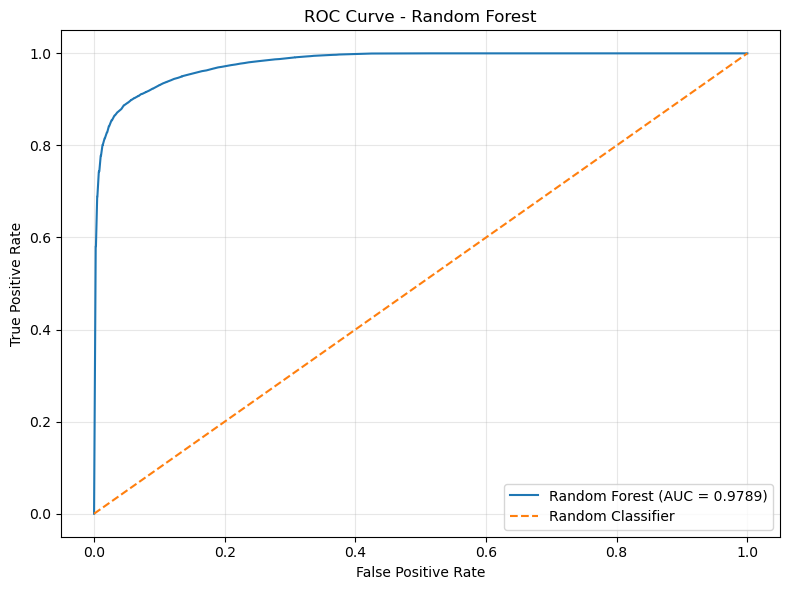

ROC-AUC Score: 0.9789


In [14]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_probabilities
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

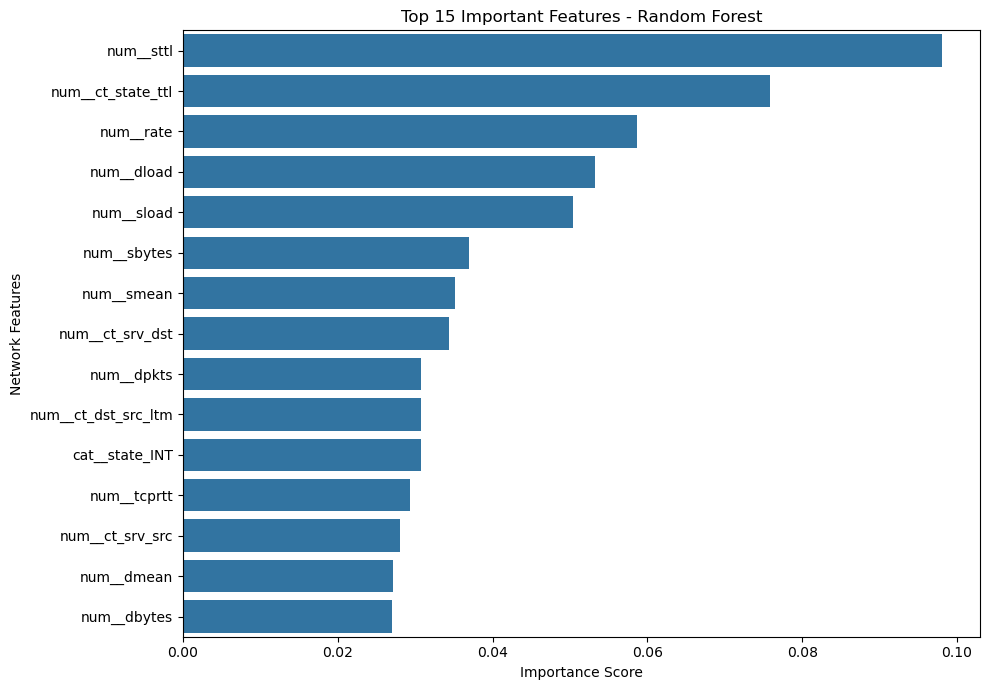

Top 15 Important Features:


,Feature,Importance
6,num__sttl,0.098053
28,num__ct_state_ttl,0.075808
5,num__rate,0.058699
9,num__dload,0.053234
8,num__sload,0.050385
3,num__sbytes,0.036909
23,num__smean,0.035144
37,num__ct_srv_dst,0.034317
2,num__dpkts,0.030806
32,num__ct_dst_src_ltm,0.030800


In [15]:
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Network Features")
plt.tight_layout()
plt.show()

print("Top 15 Important Features:")
display(top_features)

In [16]:
train_distribution = (
    y_train.value_counts(normalize=True)
    .sort_index() * 100
)

test_distribution = (
    y_test.value_counts(normalize=True)
    .sort_index() * 100
)

distribution_comparison = pd.DataFrame({
    "Training (%)": train_distribution,
    "Testing (%)": test_distribution
})

distribution_comparison.index = ["Normal (0)", "Attack (1)"]

display(distribution_comparison.round(2))

,Training (%),Testing (%)
Normal (0),31.94,44.94
Attack (1),68.06,55.06


,Training (%),Testing (%)
attack_cat,,
Normal,31.94,44.94
Generic,22.81,22.92
Exploits,19.04,13.52
Fuzzers,10.37,7.36
DoS,6.99,4.97
Reconnaissance,5.98,4.25
Analysis,1.14,0.82
Backdoor,1.00,0.71
Shellcode,0.65,0.46


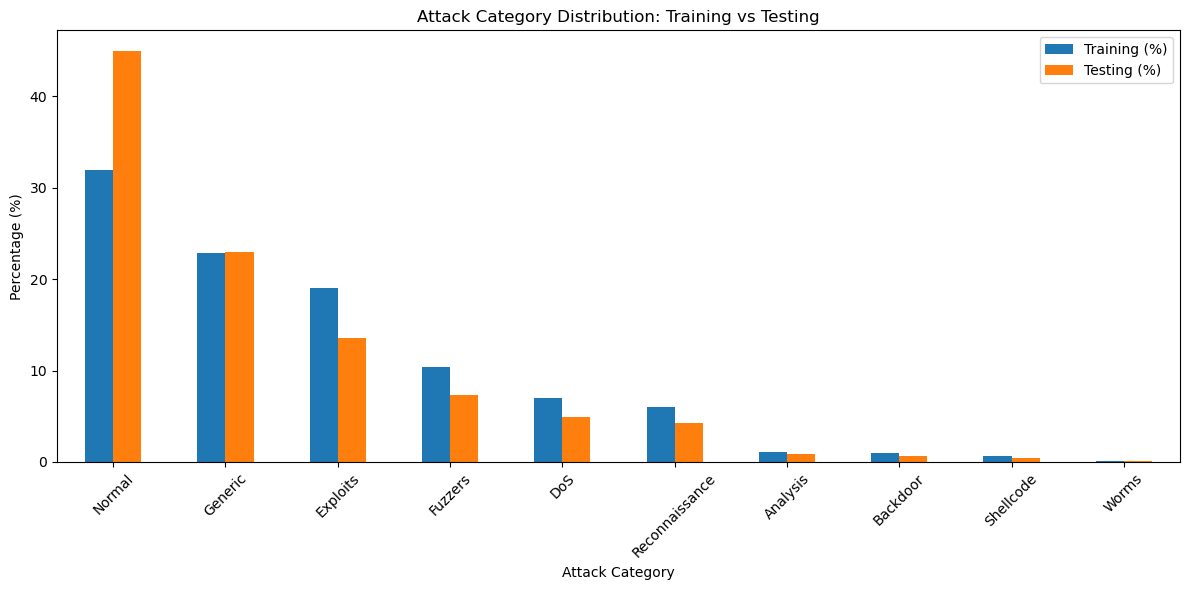

In [17]:
train_attacks = (
    train_df["attack_cat"]
    .value_counts(normalize=True) * 100
)

test_attacks = (
    test_df["attack_cat"]
    .value_counts(normalize=True) * 100
)

attack_distribution = pd.DataFrame({
    "Training (%)": train_attacks,
    "Testing (%)": test_attacks
}).fillna(0)

attack_distribution = attack_distribution.sort_values(
    by="Training (%)",
    ascending=False
)

display(attack_distribution.round(2))

attack_distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Attack Category Distribution: Training vs Testing")
plt.xlabel("Attack Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    rf_model,
    "models/random_forest_intrusion_detector.pkl"
)

print("Random Forest model saved successfully.")
print("Location: models/random_forest_intrusion_detector.pkl")

Random Forest model saved successfully.
Location: models/random_forest_intrusion_detector.pkl


In [19]:
loaded_model = joblib.load(
    "models/random_forest_intrusion_detector.pkl"
)

sample_data = X_test.iloc[:5]

sample_predictions = loaded_model.predict(sample_data)

results = pd.DataFrame({
    "Actual": y_test.iloc[:5].values,
    "Predicted": sample_predictions,
    "Result": [
        "Correct" if actual == predicted else "Incorrect"
        for actual, predicted in zip(
            y_test.iloc[:5].values,
            sample_predictions
        )
    ]
})

display(results)

print("Model loaded and predictions completed successfully.")

,Actual,Predicted,Result
0,0,1,Incorrect
1,0,1,Incorrect
2,0,1,Incorrect
3,0,1,Incorrect
4,0,1,Incorrect


Model loaded and predictions completed successfully.
